# CS781  Phase 1 Enco-Deco

Encoder-decoder Transformer with a bidirectional RoPE encoder, causal RoPE decoder, cross-attention, RMSNorm, and GeGLU. Trained with a prefix-LM objective.

In [1]:
!pip install ijson --break-system-packages -q
import os, math, json, time, random, zipfile, csv
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import login, hf_hub_download

                                                               
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
hf_token = user_secrets.get_secret("HuggingFace")


DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_GPUS = torch.cuda.device_count()
print(DEVICE, NUM_GPUS)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 2.0 MB/s eta 0:00:00
cuda 2


In [2]:
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
DATA_SOURCES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

                                                                                              
ARCH_NAME = "encdec_rope_geglu"

BPE_VOCAB_SIZE = 12000
BPE_TRAIN_CHARS = 8000000
MAX_BPE_WORDS = 100000

TRAIN_TOKENS = 300000000
VAL_TOKENS = 10000000

                                                                                                                   
ENC_LEN = 512
DEC_LEN = 400                                    
BLOCK_SIZE = ENC_LEN + DEC_LEN                                        

                                                                         
MICRO_BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 8

TRAIN_STEPS = 7500
EVAL_EVERY = 500
WARMUP_STEPS = 200
LR = 3e-4
WEIGHT_DECAY = 0.1

                                                                   
D_MODEL = 640
N_ENC_LAYERS = 6
N_DEC_LAYERS = 6
N_HEADS = 10
D_FF = 2560
DROPOUT = 0.1
ROPE_BASE = 10000.0

TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 400
TEMPERATURE = 0.8
TOP_P = 0.95
CHECKPOINT_EVERY = 250
assert MAX_GENERATION_TOKENS <= DEC_LEN

_data_tag = "-".join(s.split("/")[-1].replace(".json", "") for s in DATA_SOURCES)
RUN_ID = f"{ARCH_NAME}_{_data_tag}"
OUTPUT_DIR = f"/kaggle/working/cs781_phase1/{RUN_ID}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOKENIZER_PATH = os.path.join(OUTPUT_DIR, "bpe_tokenizer.json")
TOKENIZED_CACHE_PATH = os.path.join(OUTPUT_DIR, "tokenized_corpus.pt")
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "checkpoint.pt")
MODEL_PATH = os.path.join(OUTPUT_DIR, "model.pt")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
HELDOUT_TRUTH_PATH = os.path.join(OUTPUT_DIR, "heldout_truth.json")
HELDOUT_PRED_PATH = os.path.join(OUTPUT_DIR, "heldout_prediction.json")
LOG_PATH = "/kaggle/working/cs781_phase1/experiment_log.csv"

print(RUN_ID)


encdec_rope_geglu_train_supreme_court-train_acts-train_high_courts-train_tribunals


In [3]:
def download(path):
    return hf_hub_download(repo_id=HF_DATASET_REPO, filename=path, repo_type="dataset", token=hf_token)

train_file_paths = [download(p) for p in DATA_SOURCES]
test_file_path = download(TEST_FILE)

import ijson

CHARS_PER_TOKEN_EST = 6
CHAR_BUDGET = (TRAIN_TOKENS + VAL_TOKENS) * CHARS_PER_TOKEN_EST + BPE_TRAIN_CHARS + 5000000
MIN_RECORDS = 1000

def stream_records(path, char_budget, min_records):
    collected_chars, n = 0, 0
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            yield rec
            collected_chars += len(rec.get("text", ""))
            n += 1
            if collected_chars >= char_budget and n >= min_records:
                return

per_file_budget = CHAR_BUDGET // len(train_file_paths)
per_file_min = max(MIN_RECORDS // len(train_file_paths), 300)

records = []
for p in train_file_paths:
    records.extend(stream_records(p, per_file_budget, per_file_min))

random.Random(SEED).shuffle(records)

N_HELDOUT_DOCS = 200
heldout_records = records[-N_HELDOUT_DOCS:]
train_pool_records = records[:-N_HELDOUT_DOCS]
full_train_text = "\n".join(r["text"] for r in train_pool_records)
print(len(records), len(full_train_text))

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_tribunal(…): reconstructing file:   0%|          |  0.00B / 6.48GB            

Phase_1_Pretraining/Train/train_tribunal(…): downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

261738 1872052005


In [4]:
class ByteLevelBPETokenizer:
    SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]

    def __init__(self):
        self.merges = {}
        self.id_to_bytes = {i: bytes([i]) for i in range(256)}
        self.special_to_id = {}
        for i, tok in enumerate(self.SPECIAL_TOKENS):
            tid = 256 + i
            self.special_to_id[tok] = tid
            self.id_to_bytes[tid] = tok.encode("utf-8")

    @property
    def vocab_size(self):
        return len(self.id_to_bytes)

    @staticmethod
    def _pair_counts(sequences):
        counts = {}
        for seq, freq in sequences:
            for pair in zip(seq, seq[1:]):
                counts[pair] = counts.get(pair, 0) + freq
        return counts

    @staticmethod
    def _apply_merge(seq, pair, new_id):
        out, i = [], 0
        while i < len(seq):
            if i < len(seq) - 1 and (seq[i], seq[i + 1]) == pair:
                out.append(new_id); i += 2
            else:
                out.append(seq[i]); i += 1
        return out

    def train(self, text, vocab_size, max_words=MAX_BPE_WORDS, verbose=True):
        num_merges = vocab_size - self.vocab_size
        if num_merges <= 0:
            return self

        word_freq = {}
        for word in text.split():
            word_freq[word] = word_freq.get(word, 0) + 1
        if len(word_freq) > max_words:
            word_freq = dict(sorted(word_freq.items(), key=lambda kv: -kv[1])[:max_words])
        sequences = [[list(word.encode("utf-8")), freq] for word, freq in word_freq.items()]

        next_id = self.vocab_size
        for step in range(num_merges):
            counts = self._pair_counts(sequences)
            if not counts:
                break
            best_pair = max(counts, key=counts.get)
            self.merges[best_pair] = next_id
            self.id_to_bytes[next_id] = self.id_to_bytes[best_pair[0]] + self.id_to_bytes[best_pair[1]]
            for entry in sequences:
                entry[0] = self._apply_merge(entry[0], best_pair, next_id)
            if verbose and (step + 1) % 1000 == 0:
                print(step + 1, next_id + 1)
            next_id += 1
        return self

    def encode(self, text):
        ids = []
        for word in text.split():
            seq = list(word.encode("utf-8"))
            while len(seq) > 1:
                mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
                if not mergeable:
                    break
                pair = min(mergeable, key=lambda p: self.merges[p])
                seq = self._apply_merge(seq, pair, self.merges[pair])
            ids.extend(seq)
            ids.append(self.special_to_id["</s>"])
        return ids

    def encode_to_array(self, text, max_tokens):
        arr = np.empty(max_tokens, dtype=np.int32)
        n = 0
        for word in text.split():
            seq = list(word.encode("utf-8"))
            while len(seq) > 1:
                mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
                if not mergeable:
                    break
                pair = min(mergeable, key=lambda p: self.merges[p])
                seq = self._apply_merge(seq, pair, self.merges[pair])
            seq.append(self.special_to_id["</s>"])
            for t in seq:
                if n >= max_tokens:
                    return arr[:n]
                arr[n] = t; n += 1
        return arr[:n]

    def decode(self, ids):
        words, current = [], []
        for i in ids:
            if i == self.special_to_id["</s>"]:
                if current:
                    words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
                    current = []
            else:
                current.append(i)
        if current:
            words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
        return " ".join(words)

    def save(self, path):
        merges_serializable = {f"{a},{b}": nid for (a, b), nid in self.merges.items()}
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": merges_serializable}, f)

    @classmethod
    def load(cls, path):
        tok = cls()
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for pair_str, nid in data["merges"].items():
            a, b = (int(x) for x in pair_str.split(","))
            tok.merges[(a, b)] = nid
            tok.id_to_bytes[nid] = tok.id_to_bytes[a] + tok.id_to_bytes[b]
        return tok

In [5]:
if os.path.exists(TOKENIZER_PATH):
    tokenizer = ByteLevelBPETokenizer.load(TOKENIZER_PATH)
else:
    tokenizer = ByteLevelBPETokenizer().train(full_train_text[:BPE_TRAIN_CHARS], BPE_VOCAB_SIZE)
    tokenizer.save(TOKENIZER_PATH)

VOCAB_SIZE = tokenizer.vocab_size
print(VOCAB_SIZE)

1000 1260
2000 2260
3000 3260
4000 4260
5000 5260
6000 6260
7000 7260
8000 8260
9000 9260
10000 10260
11000 11260
12000


In [6]:
BOS_ID = tokenizer.special_to_id["<s>"]
EOS_ID = tokenizer.special_to_id["</s>"]

if os.path.exists(TOKENIZED_CACHE_PATH):
    cache = torch.load(TOKENIZED_CACHE_PATH, weights_only=False)
    train_ids, val_ids = torch.from_numpy(cache["train_ids"]), torch.from_numpy(cache["val_ids"])
else:
    all_ids = tokenizer.encode_to_array(full_train_text, TRAIN_TOKENS + VAL_TOKENS)
    split = int(len(all_ids) * (TRAIN_TOKENS / (TRAIN_TOKENS + VAL_TOKENS)))
    train_ids, val_ids = all_ids[:split].copy(), all_ids[split:].copy()
    torch.save({"train_ids": train_ids, "val_ids": val_ids}, TOKENIZED_CACHE_PATH)

del full_train_text
print(len(train_ids), len(val_ids))

def make_blocks(ids, block_size):
    n = (len(ids) // block_size) * block_size
    return torch.from_numpy(np.asarray(ids[:n], dtype=np.int64)).view(-1, block_size)

train_blocks = make_blocks(train_ids, BLOCK_SIZE)
val_blocks = make_blocks(val_ids, BLOCK_SIZE)

class BlockDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, idx):
        b = self.blocks[idx]
        enc = b[:ENC_LEN]
        tgt = b[ENC_LEN:ENC_LEN + DEC_LEN]
        dec_in = torch.cat([torch.tensor([BOS_ID], dtype=torch.long), tgt[:-1]])                                      
        return enc, dec_in, tgt

train_loader = DataLoader(BlockDataset(train_blocks), batch_size=MICRO_BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(BlockDataset(val_blocks), batch_size=MICRO_BATCH_SIZE, shuffle=False, drop_last=True)

300000000 10000000


In [7]:
def split_prompt_continuation(text, prompt_words=512, cont_words=128):
    words = text.split()
    if len(words) < prompt_words + 20:
        return None
    return " ".join(words[:prompt_words]), " ".join(words[prompt_words: prompt_words + cont_words])

heldout_truth, heldout_prompts = {}, {}
for i, rec in enumerate(heldout_records):
    r = split_prompt_continuation(rec["text"])
    if r is None:
        continue
    ex_id = str(i + 1)
    heldout_prompts[ex_id] = {"text": r[0]}
    heldout_truth[ex_id] = {"text": r[1]}

with open(HELDOUT_TRUTH_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_truth, f, ensure_ascii=False, indent=2)
print(len(heldout_truth))

74


In [8]:
class RMSNorm(nn.Module):
    """RMS normalization without mean subtraction."""
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        rms = x.pow(2).mean(dim=-1, keepdim=True)
        return self.weight * x * torch.rsqrt(rms + self.eps)


def rotate_half(x):
                                                                                    
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)


class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len, base=10000.0):
        super().__init__()
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2, dtype=torch.float32) / dim))
        freqs = torch.outer(torch.arange(max_seq_len, dtype=torch.float32), inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)
        self.register_buffer("cos", emb.cos()[None, None, :, :], persistent=False)
        self.register_buffer("sin", emb.sin()[None, None, :, :], persistent=False)

    def forward(self, x, offset=0):
        T = x.size(-2)
        cos = self.cos[:, :, offset:offset + T, :].to(x.dtype)
        sin = self.sin[:, :, offset:offset + T, :].to(x.dtype)
        return x * cos + rotate_half(x) * sin


class Attention(nn.Module):
    """
    One module for all three attention types of an encoder-decoder:
      - encoder self-attention : bidirectional, RoPE        (causal=False, rope on)
      - decoder self-attention : causal, RoPE, KV-cache      (causal=True,  rope on)
      - cross-attention        : decoder queries -> encoder memory, no RoPE, cached once
    """
    def __init__(self, d_model, n_heads, dropout=0.0, rope=None, causal=False):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_head = n_heads, d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.rope, self.causal, self.dropout = rope, causal, dropout
        self.resid_dropout = nn.Dropout(dropout)

    def _split(self, x):
        B, T, _ = x.shape
        return x.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

    def forward(self, x, context=None, cache=None, offset=0):
        B, T, C = x.shape
        q = self._split(self.q_proj(x))

        if context is not None:                                        
            if cache is not None and "k" in cache:
                k, v = cache["k"], cache["v"]
            else:
                k, v = self._split(self.k_proj(context)), self._split(self.v_proj(context))
                if cache is not None:
                    cache["k"], cache["v"] = k, v
            is_causal = False
        else:                                                         
            k, v = self._split(self.k_proj(x)), self._split(self.v_proj(x))
            if self.rope is not None:
                q, k = self.rope(q, offset), self.rope(k, offset)
            if cache is not None:                                                    
                if "k" in cache:
                    k = torch.cat([cache["k"], k], dim=2)
                    v = torch.cat([cache["v"], v], dim=2)
                cache["k"], cache["v"] = k, v
            is_causal = self.causal and cache is None

        out = F.scaled_dot_product_attention(
            q, k, v, attn_mask=None,
            dropout_p=self.dropout if self.training else 0.0,
            is_causal=is_causal,
        )
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.out_proj(out))


class GeGLU(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.gate = nn.Linear(d_model, d_ff, bias=False)
        self.up = nn.Linear(d_model, d_ff, bias=False)
        self.down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.down(F.gelu(self.gate(x)) * self.up(x)))


class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, rope, dropout):
        super().__init__()
        self.norm_attn = RMSNorm(d_model)
        self.attn = Attention(d_model, n_heads, dropout, rope=rope, causal=False)
        self.norm_ffn = RMSNorm(d_model)
        self.ffn = GeGLU(d_model, d_ff, dropout)

    def forward(self, x):
        x = x + self.attn(self.norm_attn(x))
        return x + self.ffn(self.norm_ffn(x))


class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, rope, dropout):
        super().__init__()
        self.norm_self = RMSNorm(d_model)
        self.self_attn = Attention(d_model, n_heads, dropout, rope=rope, causal=True)
        self.norm_cross = RMSNorm(d_model)
        self.cross_attn = Attention(d_model, n_heads, dropout, rope=None, causal=False)
        self.norm_ffn = RMSNorm(d_model)
        self.ffn = GeGLU(d_model, d_ff, dropout)

    def forward(self, x, memory, cache=None, offset=0):
        sc = cache["self"] if cache is not None else None
        cc = cache["cross"] if cache is not None else None
        x = x + self.self_attn(self.norm_self(x), cache=sc, offset=offset)
        x = x + self.cross_attn(self.norm_cross(x), context=memory, cache=cc)
        return x + self.ffn(self.norm_ffn(x))


class EncoderDecoderLM(nn.Module):
    """
    Prefix-LM style encoder-decoder: encoder reads the prompt (bidirectional),
    decoder generates the continuation (causal + cross-attention).
    Shared token embedding for encoder input, decoder input and the tied LM head.
    """
    def __init__(self, vocab_size, d_model, n_enc_layers, n_dec_layers, n_heads, d_ff,
                 enc_len, dec_len, dropout=0.1, rope_base=10000.0, tie_weights=True):
        super().__init__()
        self.enc_len, self.dec_len = enc_len, dec_len
        rope_len = max(enc_len, dec_len) + 8
        d_head = d_model // n_heads
        self.enc_rope = RotaryEmbedding(d_head, rope_len, rope_base)
        self.dec_rope = RotaryEmbedding(d_head, rope_len, rope_base)

        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        self.enc_blocks = nn.ModuleList([EncoderBlock(d_model, n_heads, d_ff, self.enc_rope, dropout) for _ in range(n_enc_layers)])
        self.enc_norm = RMSNorm(d_model)
        self.dec_blocks = nn.ModuleList([DecoderBlock(d_model, n_heads, d_ff, self.dec_rope, dropout) for _ in range(n_dec_layers)])
        self.dec_norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        if tie_weights:
            self.lm_head.weight = self.token_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def encode(self, enc_ids):
        if enc_ids.size(1) > self.enc_len:
            raise ValueError(f"Encoder length {enc_ids.size(1)} exceeds enc_len={self.enc_len}")
        x = self.emb_dropout(self.token_emb(enc_ids))
        for blk in self.enc_blocks:
            x = blk(x)
        return self.enc_norm(x)

    def decode(self, dec_ids, memory):
        if dec_ids.size(1) > self.dec_len:
            raise ValueError(f"Decoder length {dec_ids.size(1)} exceeds dec_len={self.dec_len}")
        x = self.emb_dropout(self.token_emb(dec_ids))
        for blk in self.dec_blocks:
            x = blk(x, memory)
        return self.lm_head(self.dec_norm(x))

    def forward(self, enc_ids, dec_in, targets=None):
        memory = self.encode(enc_ids)
        logits = self.decode(dec_in, memory)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, enc_ids, max_new_tokens, bos_id, eos_id=None, stop_after_eos=None,
                 temperature=1.0, top_p=0.95):
        """Batch-size-1 generation with self-attn KV cache + cached cross-attn K/V.
        Stops early after `stop_after_eos` word-boundary tokens (1 per word in this tokenizer)."""
        self.eval()
        assert max_new_tokens <= self.dec_len
        memory = self.encode(enc_ids)
        caches = [{"self": {}, "cross": {}} for _ in self.dec_blocks]
        cur = torch.full((enc_ids.size(0), 1), bos_id, dtype=torch.long, device=enc_ids.device)
        out, n_eos = [], 0

        for t in range(max_new_tokens):
            x = self.token_emb(cur)
            for blk, c in zip(self.dec_blocks, caches):
                x = blk(x, memory, cache=c, offset=t)
            logits = self.lm_head(self.dec_norm(x))[:, -1, :]

            probs = torch.softmax(logits / max(temperature, 1e-5), dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cumulative = torch.cumsum(sorted_probs, dim=-1)
            remove = cumulative > top_p
            remove[:, 1:] = remove[:, :-1].clone()
            remove[:, 0] = False
            sorted_probs = sorted_probs.masked_fill(remove, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            nxt = torch.gather(sorted_idx, -1, torch.multinomial(sorted_probs, 1))

            out.append(nxt)
            cur = nxt
            if stop_after_eos is not None and eos_id is not None and enc_ids.size(0) == 1:
                n_eos += int(nxt.item() == eos_id)
                if n_eos >= stop_after_eos:
                    break
        return torch.cat(out, dim=1)                                                  


In [9]:
def build_model(arch_name):
    if arch_name == "encdec_rope_geglu":
        return EncoderDecoderLM(
            vocab_size=VOCAB_SIZE, d_model=D_MODEL,
            n_enc_layers=N_ENC_LAYERS, n_dec_layers=N_DEC_LAYERS,
            n_heads=N_HEADS, d_ff=D_FF,
            enc_len=ENC_LEN, dec_len=DEC_LEN,
            dropout=DROPOUT, rope_base=ROPE_BASE, tie_weights=True,
        )
    raise ValueError(f"Unknown architecture: {arch_name}")


raw_model = build_model(ARCH_NAME).to(DEVICE)

n_params = sum(p.numel() for p in raw_model.parameters())
n_enc = sum(p.numel() for p in raw_model.enc_blocks.parameters())
n_dec = sum(p.numel() for p in raw_model.dec_blocks.parameters())
print(f"Parameters: {n_params / 1e6:.2f}M  (encoder {n_enc / 1e6:.1f}M | decoder {n_dec / 1e6:.1f}M | embeddings {raw_model.token_emb.weight.numel() / 1e6:.1f}M)")
assert 50e6 <= n_params <= 300e6

if NUM_GPUS > 1:
    model = nn.DataParallel(raw_model)
else:
    model = raw_model


Parameters: 96.17M  (encoder 39.3M | decoder 49.2M | embeddings 7.7M)


### Architecture
- **Type:** Encoder-decoder Transformer with a prefix-LM objective
- **Encoder:** 6 bidirectional RoPE self-attention layers
- **Decoder:** 6 causal RoPE self-attention layers with cross-attention
- **Normalization / FFN:** pre-RMSNorm and GeGLU
- **Embeddings:** shared input and output embeddings
- **Context:** 512 encoder tokens + 400 decoder tokens
- **Inference:** encoder runs once; decoder caches self-attention and cross-attention K/V

In [10]:
def get_lr(step, total_steps, warmup_steps, base_lr):
    if step < warmup_steps:
        return base_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * base_lr * (1 + math.cos(math.pi * progress))

def evaluate(loader, max_batches=50):
    model.eval()
    losses = []
    with torch.no_grad():
        for i, (enc, di, dt) in enumerate(loader):
            if i >= max_batches:
                break
            enc, di, dt = enc.to(DEVICE), di.to(DEVICE), dt.to(DEVICE)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                _, loss = model(enc, di, dt)
                loss = loss.mean()
            losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

def save_checkpoint(path, step, train_loss_history, val_loss_history, step_history, elapsed_seconds):
    tmp_path = path + ".tmp"
    torch.save({
        "step": step, "model_state": raw_model.state_dict(), "optimizer_state": optimizer.state_dict(),
        "scaler_state": scaler.state_dict(), "train_loss_history": train_loss_history,
        "val_loss_history": val_loss_history, "step_history": step_history, "elapsed_seconds": elapsed_seconds,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "python_rng_state": random.getstate(),
        "run_config": {"ARCH_NAME": ARCH_NAME, "D_MODEL": D_MODEL, "N_ENC_LAYERS": N_ENC_LAYERS, "N_DEC_LAYERS": N_DEC_LAYERS, "N_HEADS": N_HEADS,
                       "D_FF": D_FF, "BLOCK_SIZE": BLOCK_SIZE, "VOCAB_SIZE": VOCAB_SIZE, "ENC_LEN": ENC_LEN, "DEC_LEN": DEC_LEN, "ROPE_BASE": ROPE_BASE, "ARCH_NAME": ARCH_NAME},
    }, tmp_path)
    os.replace(tmp_path, path)

def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    cfg = ckpt["run_config"]
    mismatches = [k for k, v in cfg.items() if str(v) != str(globals()[k])]
    if mismatches:
        raise ValueError(mismatches)
    raw_model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scaler.load_state_dict(ckpt["scaler_state"])
    torch.set_rng_state(ckpt["torch_rng_state"])
    if ckpt["cuda_rng_state"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(ckpt["cuda_rng_state"])
    random.setstate(ckpt["python_rng_state"])
    return ckpt["step"], ckpt["train_loss_history"], ckpt["val_loss_history"], ckpt["step_history"], ckpt["elapsed_seconds"]


optimizer = torch.optim.AdamW(raw_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.95))
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

if os.path.exists(CHECKPOINT_PATH):
    step, train_loss_history, val_loss_history, step_history, prev_elapsed = load_checkpoint(CHECKPOINT_PATH)
else:
    step, train_loss_history, val_loss_history, step_history, prev_elapsed = 0, [], [], [], 0.0

t0 = time.time()
model.train()
def infinite_batches(loader):
    while True:
        yield from loader

data_iter = infinite_batches(train_loader)

while step < TRAIN_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM_STEPS):
        enc, di, dt = next(data_iter)
        enc, di, dt = enc.to(DEVICE), di.to(DEVICE), dt.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            _, loss = model(enc, di, dt)
            loss = loss.mean() / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(raw_model.parameters(), 1.0)
    lr_now = get_lr(step, TRAIN_STEPS, WARMUP_STEPS, LR)
    for g in optimizer.param_groups:
        g["lr"] = lr_now
    scaler.step(optimizer)
    scaler.update()
    step += 1

    if step % 50 == 0:
        train_loss_history.append(accum_loss); step_history.append(step)
        print(step, accum_loss, lr_now)

    if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
        v_loss = evaluate(val_loader)
        val_loss_history.append((step, v_loss))
        print("eval", step, v_loss, math.exp(v_loss))

    if step % CHECKPOINT_EVERY == 0 or step == TRAIN_STEPS:
        elapsed = prev_elapsed + (time.time() - t0)
        save_checkpoint(CHECKPOINT_PATH, step, train_loss_history, val_loss_history, step_history, elapsed)

training_time = prev_elapsed + (time.time() - t0)
print(training_time / 3600)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


50 4.526543378829956 7.35e-05
100 4.571011930704117 0.00014849999999999998
150 3.959948241710663 0.00022349999999999998
200 3.8542081117630005 0.0002985
250 3.5509073734283447 0.0002999666503442662
300 3.801782965660095 0.00029986388061367523
350 3.525796204805374 0.00029969172449978833
400 3.429634243249893 0.0002994502617102046
450 3.8593220114707947 0.0002991396040412394
500 3.216421753168106 0.00029875989532616347
eval 500 3.4618801164627073 31.876852405192608
550 3.2405213713645935 0.0002983113113686082
600 3.4518387019634247 0.00029779405986116967
650 2.957676649093628 0.0002972083802892476
700 3.109788179397583 0.00029655454382016466
750 3.290638118982315 0.000295832853177617
800 3.274656742811203 0.0002950436425015144
850 3.342773348093033 0.0002941872771932747
900 3.068875938653946 0.00029326415374664465
950 3.1617574393749237 0.0002922746995641247
1000 2.8888997733592987 0.0002912193727590833
eval 1000 3.043087203502655 20.969881699941382
1050 3.288149118423462 0.000290098661

2.0385054949484767 7.679124128967183


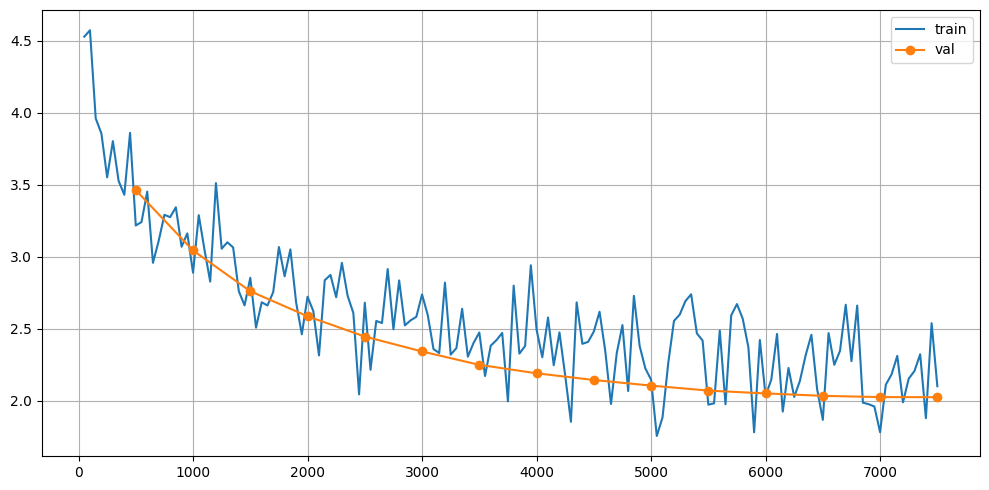

In [11]:
import matplotlib.pyplot as plt

final_val_loss = evaluate(val_loader, max_batches=200)
final_val_ppl = math.exp(final_val_loss)
print(final_val_loss, final_val_ppl)

plt.figure(figsize=(10, 5))
plt.plot(step_history, train_loss_history, label="train")
if val_loss_history:
    vs, vl = zip(*val_loss_history)
    plt.plot(vs, vl, label="val", marker="o")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

In [12]:
torch.save({
    "state_dict": raw_model.state_dict(),
    "config": {"vocab_size": VOCAB_SIZE, "d_model": D_MODEL, "n_enc_layers": N_ENC_LAYERS, "n_dec_layers": N_DEC_LAYERS,
               "n_heads": N_HEADS, "d_ff": D_FF, "enc_len": ENC_LEN, "dec_len": DEC_LEN,
               "dropout": DROPOUT, "rope_base": ROPE_BASE, "arch_name": ARCH_NAME},
}, MODEL_PATH)


In [13]:
def trim_to_words(text, n_words):
    return " ".join(text.split()[:n_words])

def generate_continuation(prompt_text, max_new_tokens=MAX_GENERATION_TOKENS):
                                                                                        
                                                                               
    prompt_ids = tokenizer.encode(prompt_text)[-ENC_LEN:]
    enc = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    out = raw_model.generate(
        enc, max_new_tokens=max_new_tokens, bos_id=BOS_ID, eos_id=EOS_ID,
        stop_after_eos=TARGET_GENERATION_WORDS + 5,                                             
        temperature=TEMPERATURE, top_p=TOP_P,
    )
    new_text = tokenizer.decode(out[0].tolist())
    return trim_to_words(new_text, TARGET_GENERATION_WORDS)

def generate_for_dataset(prompt_dict):
    predictions = {}
    for i, (ex_id, rec) in enumerate(prompt_dict.items()):
        predictions[ex_id] = {"text": generate_continuation(rec["text"])}
        if (i + 1) % 25 == 0:
            print(i + 1, len(prompt_dict))
    return predictions

raw_model.eval()


EncoderDecoderLM(
  (enc_rope): RotaryEmbedding()
  (dec_rope): RotaryEmbedding()
  (token_emb): Embedding(12000, 640)
  (emb_dropout): Dropout(p=0.1, inplace=False)
  (enc_blocks): ModuleList(
    (0-5): 6 x EncoderBlock(
      (norm_attn): RMSNorm()
      (attn): Attention(
        (q_proj): Linear(in_features=640, out_features=640, bias=False)
        (k_proj): Linear(in_features=640, out_features=640, bias=False)
        (v_proj): Linear(in_features=640, out_features=640, bias=False)
        (out_proj): Linear(in_features=640, out_features=640, bias=False)
        (rope): RotaryEmbedding()
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (norm_ffn): RMSNorm()
      (ffn): GeGLU(
        (gate): Linear(in_features=640, out_features=2560, bias=False)
        (up): Linear(in_features=640, out_features=2560, bias=False)
        (down): Linear(in_features=2560, out_features=640, bias=False)
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (enc_nor

In [14]:
heldout_preds = generate_for_dataset(heldout_prompts)
with open(HELDOUT_PRED_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_preds, f, ensure_ascii=False, indent=2)

25 74
50 74


In [15]:
!pip install bert-score --break-system-packages -q
!python /kaggle/input/datasets/adityakumar344/evaluate-phase1-script/evaluate_phase1.py --truth {HELDOUT_TRUTH_PATH} --prediction {HELDOUT_PRED_PATH}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 1.6 MB/s eta 0:00:00
python3: can't open file '/kaggle/input/datasets/adityakumar344/evaluate-phase1-script/evaluate_phase1.py': [Errno 2] No such file or directory


In [16]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

official_predictions = generate_for_dataset(test_data)
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(official_predictions, f, ensure_ascii=False, indent=2)

25 1000
50 1000
75 1000
100 1000
125 1000
150 1000
175 1000
200 1000
225 1000
250 1000
275 1000
300 1000
325 1000
350 1000
375 1000
400 1000
425 1000
450 1000
475 1000
500 1000
525 1000
550 1000
575 1000
600 1000
625 1000
650 1000
675 1000
700 1000
725 1000
750 1000
775 1000
800 1000
825 1000
850 1000
875 1000
900 1000
925 1000
950 1000
975 1000
1000 1000


In [17]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print(SUBMISSION_ZIP)

/kaggle/working/cs781_phase1/encdec_rope_geglu_train_supreme_court-train_acts-train_high_courts-train_tribunals/submission.zip


In [18]:
def log_run():
    row = {
        "run_id": RUN_ID, "arch": ARCH_NAME, "data_sources": ";".join(DATA_SOURCES),
        "vocab_size": VOCAB_SIZE, "train_tokens": len(train_ids), "block_size": BLOCK_SIZE,
        "d_model": D_MODEL, "n_enc_layers": N_ENC_LAYERS, "n_dec_layers": N_DEC_LAYERS, "n_heads": N_HEADS, "enc_len": ENC_LEN, "dec_len": DEC_LEN, "d_ff": D_FF,
        "params_M": round(n_params / 1e6, 2), "train_steps": TRAIN_STEPS,
        "final_val_loss": round(final_val_loss, 6), "final_val_ppl": round(final_val_ppl, 4),
        "training_hours": round(training_time / 3600, 3),
    }
    write_header = not os.path.exists(LOG_PATH)
    with open(LOG_PATH, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(row.keys()))
        if write_header:
            writer.writeheader()
        writer.writerow(row)

log_run()